# Notebook 11: figuras del artículo en PDF vectorial

Regenera las figuras que entran al artículo **sin reentrenar nada**: lee lo que ya está guardado (`data/`, `models/`) y las cifras verificadas de los cuadernos 03, 05 y 10. Cada figura se guarda como **PDF vectorial** en `reports/pdf/`, con las medidas de IEEEtran (3.5 in una columna, 7.16 in dos columnas).

Los cuadernos 01 a 10 no se modifican. Los PNG de `reports/` se conservan para el README y el dashboard.

**Dónde correrlo:** desde la carpeta `notebooks/`, con el entorno virtual del proyecto (necesita `shap`, `lime`, `matplotlib`, `scikit-learn` y los módulos de `src/`).

| Figura | Archivo | Origen de los datos |
|---|---|---|
| A. Distribución de clases | `fig_clases.pdf` | `data/processed/dataset_final.csv` y `data/external/corpus_ecuador_final.csv` |
| B. Prueba externa del SVM | `fig_prueba_externa.pdf` | cifras del cuaderno 05 (12 de 50 y 37 de 50) y del 03 |
| C. SHAP global | `fig_shap_global.pdf` | SVM y TF-IDF guardados; misma muestra que el cuaderno 06 |
| D. LIME con y sin la fuente | `fig_lime_fuente.pdf` | SVM y TF-IDF guardados |
| E. Resultados en español | `fig_resultados_es.pdf` | cifras del cuaderno 10 |
| F. Tópicos LDA | `fig_lda_topicos.pdf` | `lda_model.pkl` y `lda_vectorizer.pkl` |
| G. Corrección de los ejemplos LIME del cuaderno 06 | `fig_lime_ejemplos_corregido.pdf` | SVM, TF-IDF y la partición real de prueba |

In [ ]:
import sys, pickle, warnings
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter
warnings.filterwarnings("ignore")

RAIZ = Path("..") if (Path("..") / "data").exists() else Path(".")
sys.path.append(str(RAIZ / "src"))
SALIDA = RAIZ / "reports" / "pdf"
SALIDA.mkdir(parents=True, exist_ok=True)

# Medidas de IEEEtran: una columna = 3.5 in, dos columnas = 7.16 in
COL, DOBLE = 3.5, 7.16
plt.rcParams.update({
    "font.family": "serif",
    "font.serif": ["Times New Roman", "Nimbus Roman", "Liberation Serif", "DejaVu Serif"],
    "font.size": 8, "axes.titlesize": 8, "axes.labelsize": 8,
    "xtick.labelsize": 7, "ytick.labelsize": 7, "legend.fontsize": 7,
    "pdf.fonttype": 42, "ps.fonttype": 42,          # fuentes incrustadas: PDF vectorial
    "axes.spines.top": False, "axes.spines.right": False,
    "figure.dpi": 100, "savefig.bbox": "tight",
})
POS, NEG, NEUTRO = "#1B8A5A", "#C8372D", "#4C72B0"   # real/verificado, falsa/desinformacion, neutro

def guardar(fig, nombre):
    ruta = SALIDA / f"{nombre}.pdf"
    fig.savefig(ruta)
    plt.show()
    print("Guardado:", ruta)

## A. Distribución de clases en los dos corpus

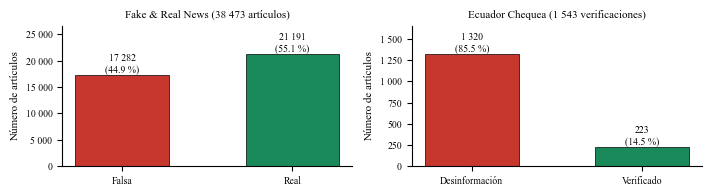

Guardado: ..\reports\pdf\fig_clases.pdf


In [ ]:
en = pd.read_csv(RAIZ / "data/processed/dataset_final.csv", usecols=["label"])["label"].value_counts().sort_index()
es = pd.read_csv(RAIZ / "data/external/corpus_ecuador_final.csv", usecols=["label_binario"])["label_binario"].value_counts().sort_index()

fig, ejes = plt.subplots(1, 2, figsize=(DOBLE, 2.0))
for ax, serie, nombres, titulo in (
    (ejes[0], en, ["Falsa", "Real"], f"Fake & Real News ({str(f'{en.sum():,}').replace(',', ' ')} artículos)"),
    (ejes[1], es, ["Desinformación", "Verificado"], f"Ecuador Chequea ({str(f'{es.sum():,}').replace(',', ' ')} verificaciones)"),
):
    barras = ax.bar(nombres, serie.values, color=[NEG, POS], edgecolor="black", linewidth=0.5, width=0.55)
    for b, v in zip(barras, serie.values):
        miles = f"{v:,}".replace(",", " ")
        ax.text(b.get_x() + b.get_width() / 2, v, f"{miles}\n({v / serie.sum() * 100:.1f} %)",
                ha="center", va="bottom", fontsize=7)
    ax.set_title(titulo)
    ax.set_ylabel("Número de artículos")
    ax.set_ylim(0, serie.max() * 1.25)
    ax.yaxis.set_major_formatter(FuncFormatter(lambda x, _: f"{int(x):,}".replace(",", " ")))
plt.tight_layout()
guardar(fig, "fig_clases")

## B. Prueba externa del SVM

Cifras tomadas del cuaderno 05: 12 de 50 noticias reales y 37 de 50 generadas con un LLM clasificadas correctamente (accuracy global 49 %), y del cuaderno 03 (accuracy de prueba del SVM, 99,45 %).

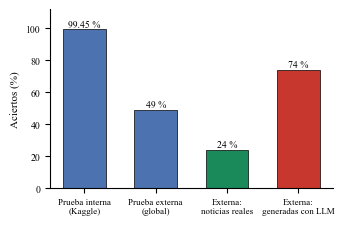

Guardado: ..\reports\pdf\fig_prueba_externa.pdf


In [ ]:
# 12/50 = 24 %, 37/50 = 74 %, global = (12 + 37) / 100 = 49 %  (cuaderno 05)
valores = {"Prueba interna\n(Kaggle)": 99.45, "Prueba externa\n(global)": (12 + 37) / 100 * 100,
           "Externa:\nnoticias reales": 12 / 50 * 100, "Externa:\ngeneradas con LLM": 37 / 50 * 100}
colores = [NEUTRO, NEUTRO, POS, NEG]
fig, ax = plt.subplots(figsize=(COL, 2.3))
barras = ax.bar(list(valores), list(valores.values()), color=colores, edgecolor="black", linewidth=0.5, width=0.6)
for b, v in zip(barras, valores.values()):
    ax.text(b.get_x() + b.get_width() / 2, v + 1.5, f"{v:g} %", ha="center", fontsize=7)
ax.set_ylabel("Aciertos (%)")
ax.set_ylim(0, 112)
ax.tick_params(axis="x", labelsize=6.5)
plt.tight_layout()
guardar(fig, "fig_prueba_externa")

## Carga del SVM, del vectorizador y de la partición de prueba

Se usa la misma función `get_tfidf_features` del cuaderno 06, para obtener exactamente la misma partición.

In [ ]:
from feature_extraction import get_tfidf_features
from preprocessing import preprocess

df = pd.read_csv(RAIZ / "data/processed/dataset_preprocessed.csv", low_memory=False)
with open(RAIZ / "models/tfidf_title_text_clean.pkl", "rb") as f:
    vectorizer = pickle.load(f)
with open(RAIZ / "models/baseline_svm_best.pkl", "rb") as f:
    svm = pickle.load(f)

X_train, X_test, y_train, y_test, _ = get_tfidf_features(df, "title_text_clean")
nombres_features = vectorizer.get_feature_names_out()
print(f"Entrenamiento: {X_train.shape[0]:,} | Prueba: {X_test.shape[0]:,} | Features: {X_test.shape[1]:,}")

Enfoque: 'title_text_clean'
  Train: 30,778 muestras | 10,000 features
  Test:  7,695 muestras  | 10,000 features
  Balance train — Falsas: 13,825 | Reales: 16,953
Entrenamiento: 30,778 | Prueba: 7,695 | Features: 10,000


## C. SHAP global

Misma muestra que el cuaderno 06: las primeras 200 filas del conjunto de prueba.

Background dataset has 30778 samples but max_samples=100. Subsampling to 100 samples for SHAP value computation. To use all samples, set max_samples=30778 when initializing the masker.


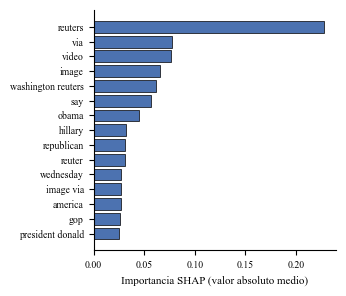

Guardado: ..\reports\pdf\fig_shap_global.pdf
Primera feature: reuters = 0.2282; segunda = 0.0779; razón = 2.93


In [ ]:
import shap

explicador = shap.LinearExplainer(svm, X_train, feature_perturbation="interventional")
shap_values = np.asarray(explicador.shap_values(X_test[:200]))
media = np.abs(shap_values).mean(axis=0)
top = np.argsort(media)[::-1][:15][::-1]

fig, ax = plt.subplots(figsize=(COL, 3.0))
ax.barh([nombres_features[i] for i in top], media[top], color=NEUTRO, edgecolor="black", linewidth=0.5)
ax.set_xlabel("Importancia SHAP (valor absoluto medio)")
plt.tight_layout()
guardar(fig, "fig_shap_global")
ordenadas = np.sort(media)[::-1]
print(f"Primera feature: {nombres_features[np.argmax(media)]} = {ordenadas[0]:.4f}; segunda = {ordenadas[1]:.4f}; razón = {ordenadas[0] / ordenadas[1]:.2f}")

## D. LIME con y sin la fuente

Los dos textos son los de los botones de ejemplo del dashboard. LIME con 5,000 variantes y semilla 42 (tarda unos minutos).

Con la fuente: P(real) = 91.0%
Sin la fuente: P(real) = 73.6%


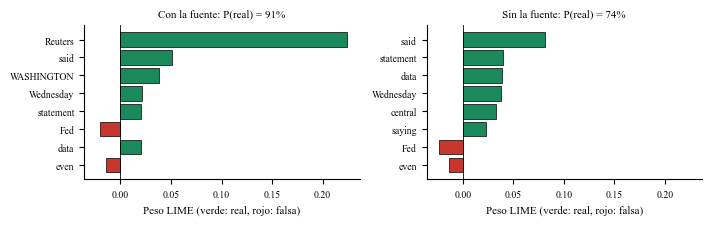

Guardado: ..\reports\pdf\fig_lime_fuente.pdf


In [ ]:
from lime.lime_text import LimeTextExplainer

CON = ("WASHINGTON (Reuters) - The U.S. Federal Reserve held interest rates steady on Wednesday, saying that inflation "
       "remains above its long-term target even as the labor market shows signs of cooling. Fed Chair said in a statement "
       "that policymakers would continue to monitor economic data closely before deciding on any future changes to "
       "borrowing costs. The decision was widely expected by analysts, who had predicted that the central bank would wait "
       "for further evidence that price pressures are easing. Stocks on Wall Street were little changed after the "
       "announcement, while Treasury yields edged lower. Economists polled by Reuters said they expect the central bank "
       "to begin cutting rates later this year if inflation continues to decline. The Fed has raised rates sharply over "
       "the past two years to bring down prices, a campaign that has increased the cost of mortgages and business loans. "
       "Officials said they remain committed to returning inflation to two percent, and that the path forward will depend "
       "on incoming data, the outlook for growth and the balance of risks facing the economy.")
SIN = CON.replace("WASHINGTON (Reuters) - ", "").replace("polled by Reuters", "polled by analysts")

def prob_real(textos):
    limpios = [preprocess(t, lemmatize=True) for t in textos]
    p1 = 1 / (1 + np.exp(-svm.decision_function(vectorizer.transform(limpios))))
    return np.column_stack([1 - p1, p1])

lime = LimeTextExplainer(class_names=["Falsa", "Real"], random_state=42)
resultados = {}
for nombre, texto in (("Con la fuente", CON), ("Sin la fuente", SIN)):
    p = float(prob_real([texto])[0][1])
    exp = lime.explain_instance(texto, prob_real, num_features=8, num_samples=5000)
    resultados[nombre] = (p, exp.as_list())
    print(f"{nombre}: P(real) = {p:.1%}")

fig, ejes = plt.subplots(1, 2, figsize=(DOBLE, 2.3), sharex=True)
for ax, (nombre, (p, lista)) in zip(ejes, resultados.items()):
    lista = sorted(lista, key=lambda t: abs(t[1]))
    ax.barh([w for w, _ in lista], [v for _, v in lista],
            color=[POS if v > 0 else NEG for _, v in lista], edgecolor="black", linewidth=0.5)
    ax.axvline(0, color="black", linewidth=0.6)
    ax.set_title(f"{nombre}: P(real) = {p:.0%}")
    ax.set_xlabel("Peso LIME (verde: real, rojo: falsa)")
plt.tight_layout()
guardar(fig, "fig_lime_fuente")

## G. Corrección de los ejemplos LIME del cuaderno 06

En el cuaderno 06 el texto de cada ejemplo se tomaba de las **últimas filas** del dataset, y la etiqueta, del conjunto de prueba. Como el dataset se armó con las noticias falsas primero y las reales después, las últimas filas son noticias reales, y el ejemplo "falsa clasificada como real" era en realidad una noticia real. Aquí el texto se toma de la fila exacta del conjunto de prueba (`df.loc[indice]`) y la predicción se calcula, no se escribe en el título.

Noticias falsas clasificadas como reales: 32 de 3457 falsas en la prueba
Falsa, clasificada como real: etiqueta FALSA, predicción REAL. Texto: apologize human right violation review country bad human right violation obama apology tour great country world continue united states hear widespread...
Real, clasificada como real: etiqueta REAL, predicción REAL. Texto: exclusive obama approve broad role force afghanistan washington reuters president barack obama approve give military great ability accompany enable af...


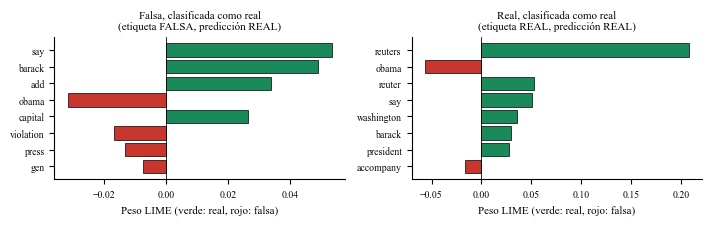

Guardado: ..\reports\pdf\fig_lime_ejemplos_corregido.pdf


In [ ]:
pred_test = svm.predict(X_test)
real = y_test.values
falsas_como_reales = y_test.index[(real == 0) & (pred_test == 1)]
reales_ok = y_test.index[(real == 1) & (pred_test == 1)]
print(f"Noticias falsas clasificadas como reales: {len(falsas_como_reales)} de {(real == 0).sum()} falsas en la prueba")

ejemplos = []
if len(falsas_como_reales):
    ejemplos.append(("Falsa, clasificada como real", falsas_como_reales[0]))
ejemplos.append(("Real, clasificada como real", reales_ok[0]))

fig, ejes = plt.subplots(1, len(ejemplos), figsize=(DOBLE if len(ejemplos) > 1 else COL, 2.3), squeeze=False)
for ax, (titulo, idx) in zip(ejes[0], ejemplos):
    texto = df.loc[idx, "title_text_clean"]
    etiqueta = "REAL" if y_test.loc[idx] == 1 else "FALSA"
    pred = "REAL" if svm.predict(vectorizer.transform([texto]))[0] == 1 else "FALSA"
    print(f"{titulo}: etiqueta {etiqueta}, predicción {pred}. Texto: {texto[:150]}...")
    exp = lime.explain_instance(texto, lambda t: np.column_stack([
        1 - 1 / (1 + np.exp(-svm.decision_function(vectorizer.transform(t)))),
        1 / (1 + np.exp(-svm.decision_function(vectorizer.transform(t))))]), num_features=8, num_samples=1500)
    lista = sorted(exp.as_list(), key=lambda t: abs(t[1]))
    ax.barh([w for w, _ in lista], [v for _, v in lista],
            color=[POS if v > 0 else NEG for _, v in lista], edgecolor="black", linewidth=0.5)
    ax.axvline(0, color="black", linewidth=0.6)
    ax.set_title(f"{titulo}\n(etiqueta {etiqueta}, predicción {pred})")
    ax.set_xlabel("Peso LIME (verde: real, rojo: falsa)")
plt.tight_layout()
guardar(fig, "fig_lime_ejemplos_corregido")

## E. Resultados en español (cuaderno 10)

Media y desviación entre las 5 particiones de la validación cruzada.

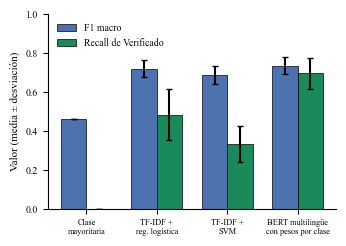

Guardado: ..\reports\pdf\fig_resultados_es.pdf


In [ ]:
modelos = ["Clase\nmayoritaria", "TF-IDF +\nreg. logística", "TF-IDF +\nSVM", "BERT multilingüe\ncon pesos por clase"]
f1 = np.array([0.461, 0.720, 0.687, 0.735]);   f1_sd = np.array([0.000, 0.043, 0.045, 0.043])
rc = np.array([0.000, 0.484, 0.332, 0.695]);   rc_sd = np.array([0.000, 0.131, 0.093, 0.082])

x = np.arange(len(modelos)); ancho = 0.36
fig, ax = plt.subplots(figsize=(COL, 2.5))
ax.bar(x - ancho / 2, f1, ancho, yerr=f1_sd, capsize=2, color=NEUTRO, edgecolor="black", linewidth=0.5, label="F1 macro")
ax.bar(x + ancho / 2, rc, ancho, yerr=rc_sd, capsize=2, color=POS, edgecolor="black", linewidth=0.5, label="Recall de Verificado")
ax.set_xticks(x); ax.set_xticklabels(modelos, fontsize=6)
ax.set_ylim(0, 1.0); ax.set_ylabel("Valor (media ± desviación)")
ax.legend(frameon=False, loc="upper left")
plt.tight_layout()
guardar(fig, "fig_resultados_es")

## F. Tópicos LDA del corpus ecuatoriano

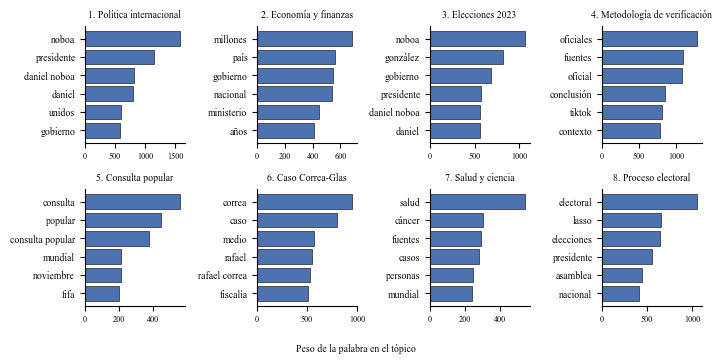

Guardado: ..\reports\pdf\fig_lda_topicos.pdf


In [ ]:
import joblib
lda = joblib.load(RAIZ / "models/lda_model.pkl")
vec_lda = joblib.load(RAIZ / "models/lda_vectorizer.pkl")
palabras = vec_lda.get_feature_names_out()
NOMBRES = ["Política internacional", "Economía y finanzas", "Elecciones 2023", "Metodología de verificación",
           "Consulta popular", "Caso Correa-Glas", "Salud y ciencia", "Proceso electoral"]   # orden real del cuaderno 09

fig, ejes = plt.subplots(2, 4, figsize=(DOBLE, 3.6))
for i, ax in enumerate(ejes.ravel()):
    top = lda.components_[i].argsort()[::-1][:6][::-1]
    ax.barh([palabras[j] for j in top], lda.components_[i][top], color=NEUTRO, edgecolor="black", linewidth=0.4)
    ax.set_title(f"{i + 1}. {NOMBRES[i]}", fontsize=7)
    ax.tick_params(axis="x", labelsize=6)
fig.supxlabel("Peso de la palabra en el tópico", fontsize=7)
plt.tight_layout()
guardar(fig, "fig_lda_topicos")

## Cómo usar los PDF en Overleaf

1. Sube los archivos de `reports/pdf/` a una carpeta `figuras/` del proyecto.
2. En el `.tex`: `\includegraphics[width=\columnwidth]{figuras/fig_shap_global.pdf}` para una columna, o `\begin{figure*}` con `width=\textwidth` para dos columnas.
3. Cada figura lleva su `\caption` y su `\label`.

## H. Menciones de plataformas en las verificaciones

Cuenta cuántas verificaciones mencionan cada plataforma y cuántas de ellas están en cada clase. Mide menciones en el texto de la verificación, no el canal por el que circuló el contenido. Sustenta la corrección de la afirmación "TikTok es el principal vector" del cuaderno 09.

In [ ]:
c = pd.read_csv(RAIZ / "data/external/corpus_ecuador_final.csv")
txt = c["contenido"].fillna("").str.lower()
plataformas = {"TikTok": "tiktok", "Facebook": "facebook", "WhatsApp": "whatsapp", "Twitter / X": "twitter",
               "YouTube": "youtube", "Instagram": "instagram", "Telegram": "telegram"}
filas = []
for nombre, patron in plataformas.items():
    m = txt.str.contains(patron, regex=False)
    filas.append({"Plataforma": nombre, "Artículos": int(m.sum()), "% del corpus": round(m.mean() * 100, 1),
                  "En Desinformación": int((m & (c["label_binario"] == 0)).sum()),
                  "En Verificado": int((m & (c["label_binario"] == 1)).sum())})
print(pd.DataFrame(filas).sort_values("Artículos", ascending=False).to_string(index=False))

 Plataforma  Artículos  % del corpus  En Desinformación  En Verificado
   Facebook        898          58.2                765            133
Twitter / X        606          39.3                505            101
     TikTok        405          26.2                360             45
    YouTube        148           9.6                128             20
  Instagram        126           8.2                106             20
   WhatsApp         33           2.1                 32              1
   Telegram         12           0.8                 12              0
